<a href="https://colab.research.google.com/github/jumanazez/DSproject/blob/main/Phase3_Model_Evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Phase 3: Model Evaluation and Comparison**

## Thmanyah Podcast Engagement Analysis

This notebook evaluates and compares the three regression models developed in Phase 3:

1. **Baseline** – Dummy Regressor (median strategy)
2. **Linear Regression**
3. **Random Forest Regressor**

All models are evaluated on **the same test set (140 episodes)** created in the data-preparation notebook (80/20 split, `random_state=42`). The data is **not re-split**: the split is recreated with the same seed only to recover the test-set features, and the result is checked against the saved predictions file.

The Linear Regression and Random Forest predictions are taken directly from `phase3_model_predictions.csv`, produced in the model-development notebook.

## 1. Loading the Data and Predictions

Required files (upload them to Colab before running):
- `thmanyah_cleaned_dataset.csv` – cleaned dataset from Phase 2
- `phase3_model_predictions.csv` – actual views and model predictions for the 140 test episodes

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

df = pd.read_csv("thmanyah_cleaned_dataset.csv")
predictions_df = pd.read_csv("phase3_model_predictions.csv")

print("Dataset:", df.shape)
print("Predictions:", predictions_df.shape)
display(predictions_df.head())

Dataset: (698, 17)
Predictions: (140, 3)


,Actual_Views,Linear_Regression_Predictions,Random_Forest_Predictions
0,320583,4.749236e+05,208394.40
1,114521,1.488904e+06,2059131.27
2,77259,2.168092e+05,106417.92
3,231003,5.054706e+05,145186.91
4,71534,-2.590325e+05,174319.80


## 2. Recovering the Same Train/Test Split

The same features, test size and random seed used in the baseline notebook are applied. The recovered test-set target values are compared with the `Actual_Views` column of the predictions file to confirm that **exactly the same 140 test episodes, in the same order,** are being evaluated.

In [2]:
features = ["podcast", "topic", "duration_minutes", "year", "month", "day_of_week"]
X = df[features]
y = df["views"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

same_test_set = np.array_equal(y_test.to_numpy(), predictions_df["Actual_Views"].to_numpy())
print("Test set identical to the predictions file:", same_test_set)
assert same_test_set, "Test set does not match - check the dataset file!"

Training: (558, 6)
Testing: (140, 6)
Test set identical to the predictions file: True


## 3. Baseline Predictions

The baseline predictions are not stored in the predictions file, so the same Dummy Regressor (median strategy) with the same preprocessing is re-fitted on the training set. Because the Dummy Regressor always predicts the training median, the result is identical to the baseline notebook.

In [3]:
categorical_features = ["podcast", "topic", "day_of_week"]
numeric_features = ["duration_minutes", "year", "month"]

def make_preprocessor(cat_cols):
    return ColumnTransformer(transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("num", "passthrough", numeric_features)
    ])

baseline_model = Pipeline(steps=[
    ("preprocessor", make_preprocessor(categorical_features)),
    ("model", DummyRegressor(strategy="median"))
])
baseline_model.fit(X_train, y_train)

predictions = {
    "Baseline": baseline_model.predict(X_test),
    "Linear Regression": predictions_df["Linear_Regression_Predictions"].to_numpy(),
    "Random Forest": predictions_df["Random_Forest_Predictions"].to_numpy(),
}
y_true = predictions_df["Actual_Views"].to_numpy()

print("Baseline prediction (training median):", predictions["Baseline"][0])

Baseline prediction (training median): 145127.0


## 4. Evaluation Metrics

Three regression metrics are used:

| Metric | Meaning | Why it is used |
|---|---|---|
| **MAE** | Average absolute difference between actual and predicted views | Easy to interpret in "views"; not dominated by a single extreme episode |
| **RMSE** | Square root of the mean squared error | Penalises large errors more heavily, showing how badly a model misses viral episodes |
| **R²** | Proportion of variance in views explained by the model | Shows whether the model is better than simply predicting the average (R² ≤ 0 means no better) |

In [4]:
def evaluate(y_actual, y_pred):
    return {
        "MAE": mean_absolute_error(y_actual, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_actual, y_pred)),
        "R²": r2_score(y_actual, y_pred),
    }

results = pd.DataFrame({name: evaluate(y_true, p) for name, p in predictions.items()}).T
results.index.name = "Model"

display(results.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}", "R²": "{:.4f}"}))
print(results.round(4))

,MAE,RMSE,R²
Model,,,
Baseline,"1,568,734","13,794,876",-0.0120
Linear Regression,"1,751,237","13,591,380",0.0176
Random Forest,"1,692,045","13,625,821",0.0126


                            MAE          RMSE      R²
Model                                                
Baseline           1.568734e+06  1.379488e+07 -0.0120
Linear Regression  1.751237e+06  1.359138e+07  0.0176
Random Forest      1.692045e+06  1.362582e+07  0.0126


### 4.1 Interpretation of the Main Comparison

- On the original view scale, **no model clearly outperforms the baseline**. The Dummy Regressor actually has the **lowest MAE**, while Linear Regression and Random Forest achieve only marginally higher R² values (close to 0).
- RMSE is roughly **8–9 times larger than MAE** for every model, which indicates that a small number of episodes produce extremely large errors.

The next cells investigate why.

## 5. Effect of the Extreme Episode (Outlier Analysis)

The EDA in Phase 2 showed that views are highly right-skewed. The test set contains the most-viewed episode in the whole dataset.

In [5]:
top = int(np.argmax(y_true))
print("Highest actual views in test set:", f"{y_true[top]:,}")
print("Share of total test-set views:", f"{y_true[top] / y_true.sum():.1%}")
print("Median test-set views:", f"{np.median(y_true):,.0f}")
print("Episode features:", X_test.iloc[top].to_dict())
for name, p in predictions.items():
    print(f"  {name} prediction: {p[top]:,.0f}")

Highest actual views in test set: 162,410,493
Share of total test-set views: 70.3%
Median test-set views: 143,238
Episode features: {'podcast': 'Fanjan', 'topic': 'Society & Personal Development', 'duration_minutes': 183.15, 'year': 2022, 'month': 11, 'day_of_week': 'Wednesday'}
  Baseline prediction: 145,127
  Linear Regression prediction: 2,393,191
  Random Forest prediction: 3,328,335


In [6]:
mask = np.arange(len(y_true)) != top
results_no_outlier = pd.DataFrame(
    {name: evaluate(y_true[mask], p[mask]) for name, p in predictions.items()}
).T
results_no_outlier.index.name = "Model"
print("Metrics on 139 test episodes (most-viewed episode excluded):")
print(results_no_outlier.round(4))

Metrics on 139 test episodes (most-viewed episode excluded):
                           MAE          RMSE      R²
Model                                               
Baseline           412642.9640  1.497615e+06 -0.0570
Linear Regression  612632.1306  1.357231e+06  0.1319
Random Forest      559741.9010  2.221033e+06 -1.3247


A single episode accounts for roughly 70% of all test-set views, and no model can predict it from duration, topic and publication date alone. This one episode dominates RMSE and R². When it is excluded, the models' relative behaviour changes (Linear Regression has the best R²; Random Forest's R² becomes strongly negative because it predicts some very large values), but **none of the models beats the baseline on MAE**.

This shows that predicting raw view counts directly is strongly affected by the skewed distribution, so the problem is examined on a logarithmic scale next.

## 6. Evaluation on the Log Scale

Because views span from about 16 thousand to 162 million, errors are also measured on `log(1 + views)`. On this scale an error of 1.0 means the prediction is off by a factor of about 2.7, regardless of whether the episode is small or viral, so every episode contributes fairly.

Negative Linear Regression predictions are clipped to 0 before taking the logarithm (views cannot be negative).

In [7]:
log_true = np.log1p(y_true)
results_log = pd.DataFrame(
    {name: evaluate(log_true, np.log1p(np.clip(p, 0, None))) for name, p in predictions.items()}
).T
results_log.index.name = "Model"
print("Metrics on log(1 + views):")
print(results_log.round(4))

for name, p in predictions.items():
    print(f"{name}: negative predictions = {(p < 0).sum()}")

Metrics on log(1 + views):
                      MAE    RMSE       R²
Model                                     
Baseline           0.9694  1.3411  -0.0506
Linear Regression  4.2710  6.4117 -23.0137
Random Forest      0.8445  1.1032   0.2891
Baseline: negative predictions = 0
Linear Regression: negative predictions = 41
Random Forest: negative predictions = 0


On the log scale the picture is clearer:

- **Random Forest** is the only model with a clearly positive R² and the lowest log-scale MAE, so it captures real patterns in the data.
- **Linear Regression** performs very poorly on this scale because 41 of its predictions are negative (impossible view counts).

## 7. Improvement Experiment: Log-Transformed Target

Since the main limitation is the skewness of `views`, both algorithms were re-trained with the **same features, preprocessing and train/test split**, but with the target transformed using `log(1 + views)` during training. Predictions are converted back to the original scale with `exp(x) − 1`, so they are evaluated in exactly the same way as the original models.

This is a configuration change, not a new data split, so the comparison remains fair.

In [8]:
def make_log_model(regressor, cat_cols=categorical_features):
    return Pipeline(steps=[
        ("preprocessor", make_preprocessor(cat_cols)),
        ("model", TransformedTargetRegressor(
            regressor=regressor, func=np.log1p, inverse_func=np.expm1))
    ])

lr_log = make_log_model(LinearRegression()).fit(X_train, y_train)
rf_log = make_log_model(RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)).fit(X_train, y_train)

predictions["Linear Regression (log target)"] = lr_log.predict(X_test)
predictions["Random Forest (log target)"] = rf_log.predict(X_test)

print("Negative predictions (LR log):", (predictions["Linear Regression (log target)"] < 0).sum())
print("Negative predictions (RF log):", (predictions["Random Forest (log target)"] < 0).sum())

Negative predictions (LR log): 0
Negative predictions (RF log): 0


In [9]:
summary = pd.DataFrame({
    name: {
        "MAE": mean_absolute_error(y_true, p),
        "RMSE": np.sqrt(mean_squared_error(y_true, p)),
        "R²": r2_score(y_true, p),
        "MAE (excl. top episode)": mean_absolute_error(y_true[mask], p[mask]),
        "R² (excl. top episode)": r2_score(y_true[mask], p[mask]),
        "Log MAE": mean_absolute_error(log_true, np.log1p(np.clip(p, 0, None))),
        "Log R²": r2_score(log_true, np.log1p(np.clip(p, 0, None))),
    }
    for name, p in predictions.items()
}).T
summary.index.name = "Model"
print(summary.round(4).to_string())

                                         MAE          RMSE      R²  MAE (excl. top episode)  R² (excl. top episode)  Log MAE   Log R²
Model                                                                                                                                
Baseline                        1.568734e+06  1.379488e+07 -0.0120              412642.9640                 -0.0570   0.9694  -0.0506
Linear Regression               1.751237e+06  1.359138e+07  0.0176              612632.1306                  0.1319   4.2710 -23.0137
Random Forest                   1.692045e+06  1.362582e+07  0.0126              559741.9010                 -1.3247   0.8445   0.2891
Linear Regression (log target)  1.510134e+06  1.370208e+07  0.0015              360839.7399                  0.0537   0.7683   0.3661
Random Forest (log target)      1.491569e+06  1.361410e+07  0.0143              349016.4155                  0.1525   0.6910   0.4862


The log-target **Random Forest** achieves the best result on almost every metric: the lowest MAE (on all 140 episodes and when the top episode is excluded), the highest R² once the viral episode is excluded, and the lowest log-scale error. Its log-scale R² of about 0.49 means it explains roughly half of the variation in (log) views. RMSE is almost identical for all models (13.6–13.8 million) because it is driven by the single viral episode that no model can predict.

## 8. Comparison Charts

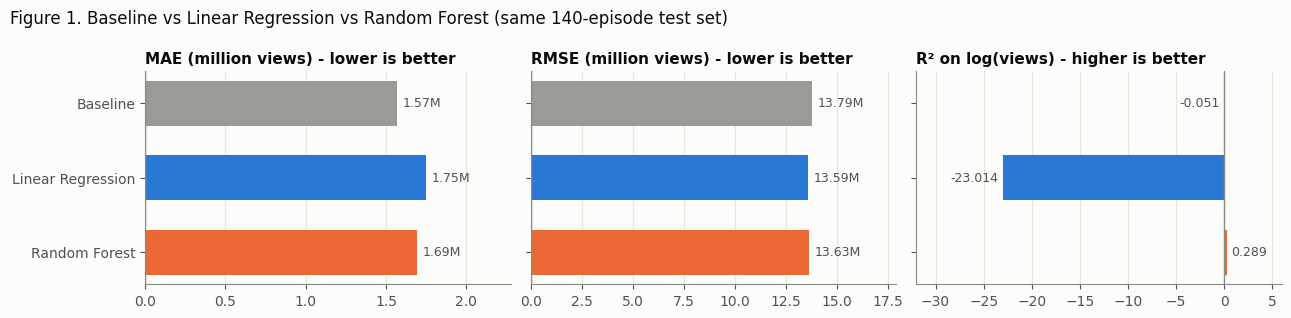

In [10]:
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.edgecolor": "#8a8984",
                     "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
                     "ytick.color": "#52514e", "figure.facecolor": "#fcfcfb",
                     "axes.facecolor": "#fcfcfb"})
COLORS = {"Baseline": "#9b9a94", "Linear Regression": "#2a78d6", "Random Forest": "#eb6834",
          "Linear Regression (log target)": "#86b6ef", "Random Forest (log target)": "#1baf7a"}
INK = "#0b0b0b"

def bar_panel(ax, values, title, fmt, names):
    ypos = np.arange(len(names))[::-1]
    ax.barh(ypos, values, color=[COLORS[n] for n in names], height=0.6)
    ax.set_yticks(ypos, names)
    ax.set_title(title, loc="left", fontsize=11, color=INK, fontweight="bold")
    ax.axvline(0, color="#8a8984", lw=1)
    ax.xaxis.grid(True, color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
    span = max(abs(v) for v in values)
    for yp, v in zip(ypos, values):
        ax.text(v + (span * 0.02 if v >= 0 else -span * 0.02), yp, fmt(v), va="center",
                ha="left" if v >= 0 else "right", fontsize=9, color="#52514e")
    ax.set_xlim(min(0, min(values)) - span * 0.35 * (min(values) < 0), span * 1.3)

main = ["Baseline", "Linear Regression", "Random Forest"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
bar_panel(axes[0], [results.loc[n, "MAE"] / 1e6 for n in main], "MAE (million views) - lower is better", lambda v: f"{v:.2f}M", main)
bar_panel(axes[1], [results.loc[n, "RMSE"] / 1e6 for n in main], "RMSE (million views) - lower is better", lambda v: f"{v:.2f}M", main)
bar_panel(axes[2], [results_log.loc[n, "R²"] for n in main], "R² on log(views) - higher is better", lambda v: f"{v:.3f}", main)
axes[2].set_xlim(-32, 6)
fig.suptitle("Figure 1. Baseline vs Linear Regression vs Random Forest (same 140-episode test set)",
             x=0.01, ha="left", fontsize=12, color=INK)
fig.tight_layout()
fig.savefig("fig1_model_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

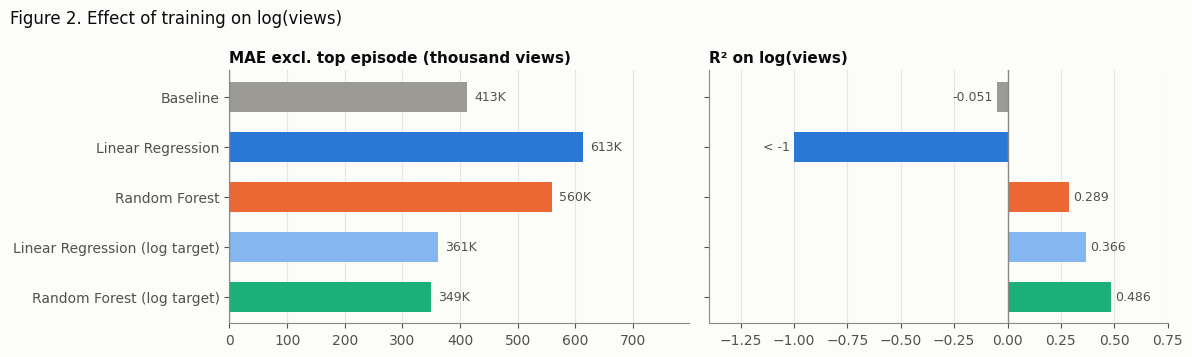

In [11]:
order = ["Baseline", "Linear Regression", "Random Forest",
         "Linear Regression (log target)", "Random Forest (log target)"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
bar_panel(axes[0], [summary.loc[n, "MAE (excl. top episode)"] / 1e3 for n in order],
          "MAE excl. top episode (thousand views)", lambda v: f"{v:,.0f}K", order)
bar_panel(axes[1], [max(summary.loc[n, "Log R²"], -1) for n in order],
          "R² on log(views)", lambda v: f"{v:.3f}" if v > -1 else "< -1", order)
axes[1].set_xlim(-1.4, 0.75)
fig.suptitle("Figure 2. Effect of training on log(views)", x=0.01, ha="left", fontsize=12, color=INK)
fig.tight_layout()
fig.savefig("fig2_log_target_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

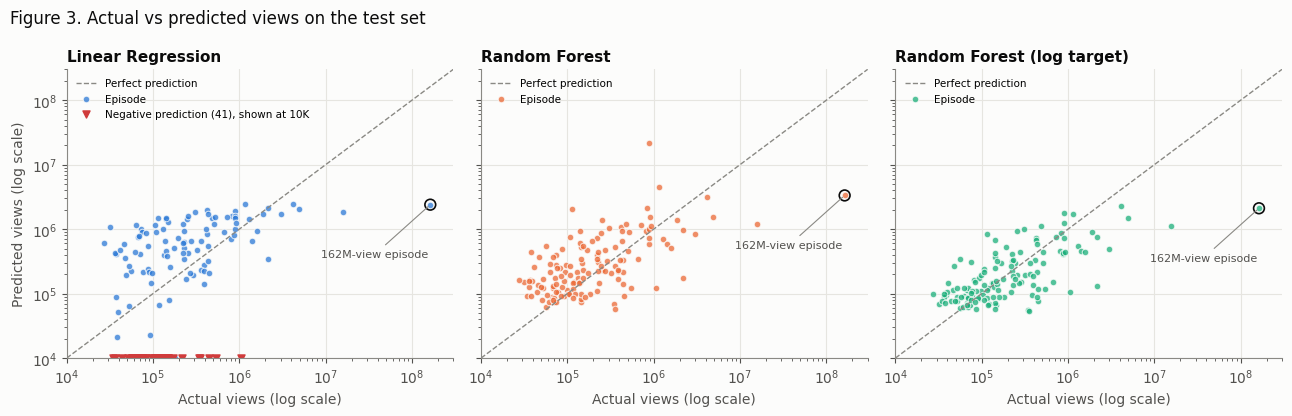

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharex=True, sharey=True)
lims = (1e4, 3e8)
for ax, name in zip(axes, ["Linear Regression", "Random Forest", "Random Forest (log target)"]):
    p = np.clip(predictions[name], 1e4, None)
    neg = predictions[name] <= 0
    ax.plot(lims, lims, color="#8a8984", lw=1, ls="--", label="Perfect prediction")
    ax.scatter(y_true[~neg], p[~neg], s=22, color=COLORS[name], alpha=0.75,
               edgecolor="#fcfcfb", linewidth=0.8, label="Episode")
    if neg.any():
        ax.scatter(y_true[neg], p[neg], s=26, marker="v", color="#d03b3b",
                   label=f"Negative prediction ({neg.sum()}), shown at 10K")
    ax.scatter([y_true[top]], [p[top]], s=60, facecolor="none", edgecolor=INK, lw=1.2)
    ax.annotate("162M-view episode", (y_true[top], p[top]), xytext=(-40, -38),
                textcoords="offset points", fontsize=8, color="#52514e", ha="center",
                arrowprops={"arrowstyle": "-", "color": "#8a8984", "lw": 0.8})
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_title(name, loc="left", fontsize=11, color=INK, fontweight="bold")
    ax.set_xlabel("Actual views (log scale)")
    ax.grid(True, color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
    ax.legend(fontsize=7.5, frameon=False, loc="upper left")
axes[0].set_ylabel("Predicted views (log scale)")
fig.suptitle("Figure 3. Actual vs predicted views on the test set", x=0.01, ha="left", fontsize=12, color=INK)
fig.tight_layout()
fig.savefig("fig3_actual_vs_predicted.png", dpi=200, bbox_inches="tight")
plt.show()

## 9. Best Model Selection

| Criterion | Best model |
|---|---|
| MAE (original scale) | Random Forest (log target) |
| R² excluding the viral episode | Random Forest (log target) |
| RMSE (original scale) | Linear Regression (difference between all models is < 2% because of one viral episode) |
| R² on log(views) | Random Forest (log target) |
| Realistic predictions (no negative views) | Random Forest / Random Forest (log target) |

**Among the three required models**, Random Forest is preferred over Linear Regression: it never predicts negative views and it is the only one with a positive log-scale R², although on the raw scale it does not clearly beat the baseline.

**Final selected model: Random Forest Regressor trained on log(1 + views).** It is the best model on almost every metric, and is a configuration of the same Random Forest algorithm developed in the modelling notebook.

In [13]:
best_name = summary["Log R²"].idxmax()
print("Best model (by log-scale R²):", best_name)
print(summary.loc[best_name].round(4))

Best model (by log-scale R²): Random Forest (log target)
MAE                        1.491569e+06
RMSE                       1.361410e+07
R²                         1.430000e-02
MAE (excl. top episode)    3.490164e+05
R² (excl. top episode)     1.525000e-01
Log MAE                    6.910000e-01
Log R²                     4.862000e-01
Name: Random Forest (log target), dtype: float64


## 10. Factors Associated with Views (Feature Importance)

**Permutation importance** is used to measure how much each original feature contributes to the final model. Each feature is randomly shuffled on the test set and the drop in log-scale R² is recorded; a larger drop means the model relies more on that feature. Unlike the built-in tree importance, this works on the original six features (not the one-hot columns), so `topic` is assessed as one variable.

In [14]:
def log_r2_scorer(estimator, X_, y_):
    return r2_score(np.log1p(y_), np.log1p(np.clip(estimator.predict(X_), 0, None)))

perm = permutation_importance(rf_log, X_test, y_test, n_repeats=30,
                              random_state=42, scoring=log_r2_scorer)
importance = pd.DataFrame({
    "Feature": features,
    "Importance (drop in log R²)": perm.importances_mean,
    "Std": perm.importances_std,
}).sort_values("Importance (drop in log R²)", ascending=False).reset_index(drop=True)
print(importance.round(4))

            Feature  Importance (drop in log R²)     Std
0           podcast                       0.4316  0.0812
1  duration_minutes                       0.3861  0.0796
2              year                       0.2827  0.0463
3             month                       0.0218  0.0155
4       day_of_week                       0.0116  0.0125
5             topic                      -0.0041  0.0170


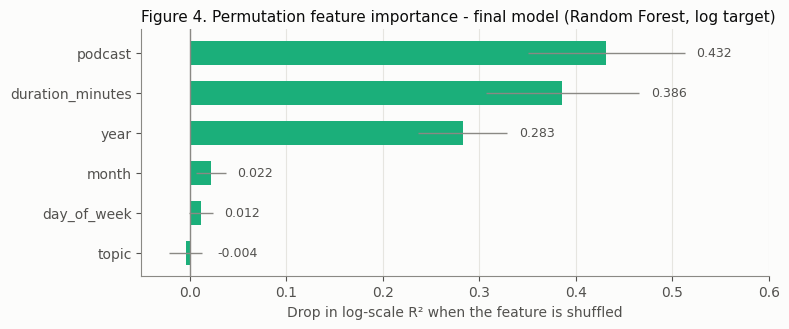

In [15]:
imp = importance.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(imp["Feature"], imp["Importance (drop in log R²)"], xerr=imp["Std"],
        color="#1baf7a", height=0.6, error_kw={"ecolor": "#8a8984", "lw": 1})
for i, (v, sd) in enumerate(zip(imp["Importance (drop in log R²)"], imp["Std"])):
    ax.text(max(v, 0) + sd + 0.012, i, f"{v:.3f}", va="center", fontsize=9, color="#52514e")
ax.axvline(0, color="#8a8984", lw=1)
ax.set_xlim(-0.05, 0.6)
ax.xaxis.grid(True, color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
ax.set_xlabel("Drop in log-scale R² when the feature is shuffled")
ax.set_title("Figure 4. Permutation feature importance - final model (Random Forest, log target)",
             loc="left", fontsize=11, color=INK)
fig.tight_layout()
fig.savefig("fig4_feature_importance.png", dpi=200, bbox_inches="tight")
plt.show()

## 11. Does Episode Topic Improve Prediction?

To connect the modelling results to the project's research question, the final model is re-trained **without the `topic` feature** (same split, same settings) and compared with the full model.

In [16]:
features_no_topic = ["podcast", "duration_minutes", "year", "month", "day_of_week"]
rf_log_no_topic = make_log_model(
    RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    cat_cols=["podcast", "day_of_week"]
).fit(X_train[features_no_topic], y_train)
p_no_topic = rf_log_no_topic.predict(X_test[features_no_topic])
p_topic = predictions["Random Forest (log target)"]

topic_effect = pd.DataFrame({
    "With topic": {"MAE": mean_absolute_error(y_true, p_topic),
                   "Log MAE": mean_absolute_error(log_true, np.log1p(p_topic)),
                   "Log R²": r2_score(log_true, np.log1p(p_topic))},
    "Without topic": {"MAE": mean_absolute_error(y_true, p_no_topic),
                      "Log MAE": mean_absolute_error(log_true, np.log1p(p_no_topic)),
                      "Log R²": r2_score(log_true, np.log1p(p_no_topic))},
}).T
print(topic_effect.round(4))

                        MAE  Log MAE  Log R²
With topic     1.491569e+06   0.6910  0.4862
Without topic  1.489264e+06   0.6925  0.4861


In [17]:
test_df = X_test.copy()
test_df["Actual"] = y_true
test_df["Predicted"] = p_topic
test_df["Abs log error"] = np.abs(np.log1p(y_true) - np.log1p(p_topic))

by_topic = test_df.groupby("topic").agg(
    Episodes=("Actual", "size"),
    Median_actual=("Actual", "median"),
    Median_predicted=("Predicted", "median"),
    Mean_abs_log_error=("Abs log error", "mean"),
).sort_values("Episodes", ascending=False)
print(by_topic.round(2).to_string())

by_podcast = test_df.groupby("podcast").agg(
    Episodes=("Actual", "size"),
    Median_actual=("Actual", "median"),
    Median_predicted=("Predicted", "median"),
).sort_values("Median_actual", ascending=False)
print()
print(by_podcast.round(0).to_string())

                                Episodes  Median_actual  Median_predicted  Mean_abs_log_error
topic                                                                                        
Other                                 63       219613.0         149419.37                0.64
Business & Finance                    23       147294.0         121876.31                0.74
Sports                                15        77259.0          76197.94                0.25
Society & Personal Development        10       180271.5         289787.71                1.13
Technology                             9       169010.0         150475.93                0.92
Politics & Government                  7       141540.0         410676.01                0.92
History & Culture                      6       342112.0         221278.27                0.94
Health                                 2       434015.0         477846.30                0.51
Economics                              2       498337.0     

## 12. Key Findings

1. **Predicting raw view counts is difficult.** On the original scale, Linear Regression and Random Forest do not meaningfully outperform the median baseline, because views are extremely skewed and one viral episode (≈162 million views) represents about 70% of all test-set views.
2. **Linear Regression is unsuitable for this target**: 41 of its 140 predictions (29%) are negative, which is impossible for view counts.
3. **Random Forest trained on log(views) is the best model.** It gives the lowest MAE and explains about half of the variation in log views (log R² ≈ 0.49), compared with ≈0.29 for the original Random Forest and below 0 for the baseline.
4. **The most important factors** for the final model are the **podcast (channel)**, **episode duration** and **publication year**. Month and day of the week matter very little.
5. **Topic does not add measurable predictive value.** Its permutation importance is about zero, and removing it changes log R² only from 0.488 to 0.486. This suggests that the differences in views between topics observed in the EDA are largely explained by which podcast publishes the episode, how long it is and when it was published.

In [18]:
# Save evaluation outputs for the report, poster and presentation
results.round(4).to_csv("phase3_evaluation_results.csv")
summary.round(4).to_csv("phase3_evaluation_summary_all_models.csv")
importance.round(4).to_csv("phase3_feature_importance.csv", index=False)
print("Saved: phase3_evaluation_results.csv, phase3_evaluation_summary_all_models.csv, phase3_feature_importance.csv")
print("Saved figures: fig1_model_comparison.png, fig2_log_target_comparison.png, fig3_actual_vs_predicted.png, fig4_feature_importance.png")

Saved: phase3_evaluation_results.csv, phase3_evaluation_summary_all_models.csv, phase3_feature_importance.csv
Saved figures: fig1_model_comparison.png, fig2_log_target_comparison.png, fig3_actual_vs_predicted.png, fig4_feature_importance.png
